# 🏦 Projet RAG Bankily
Ce notebook a été restructuré pour offrir une séparation claire entre les installations, les configurations de modèles, la logique métier (RAG) et l'application finale.

In [3]:
# 1. Installation des dépendances
!pip install -q -U evaluate rouge_score bert_score matplotlib seaborn pandas
!pip install -q -U langchain langchain-community langchain-text-splitters langchain-core langchain-huggingface
!pip install -q -U google-generativeai sentence-transformers faiss-cpu rank_bm25 pypdf
!pip install -q gradio

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 114.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 119.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.3 which is incompatible.
dask-cudf-cu12 26.2.1 requires 

In [4]:
# 2. Importation de toutes les bibliothèques
import os
import re
import numpy as np
import torch
from IPython.display import Markdown, display

# Langchain & Core
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.llms import HuggingFacePipeline
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# NLP & Modèles de Recherche
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, pipeline

/tmp/ipykernel_11817/1481421968.py:11: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [6]:
# 3. Montage du Drive et Configuration des chemins
from google.colab import drive
drive.mount('/content/drive')

path_to_data = '/content/drive/MyDrive/Colab Notebooks (1)/data_rag'

import os
if os.path.exists(path_to_data):
    print(f"✅ Dossier trouvé : {len(os.listdir(path_to_data))} fichiers détectés.")
else:
    print("❌ Erreur : Le chemin spécifié n'existe pas. Vérifiez le nom du dossier.")


Mounted at /content/drive
✅ Dossier trouvé : 35 fichiers détectés.


## Configuration des Modèles

In [7]:
# 4. Configuration de l'Embedding et du Re-ranker

# Modèle d'Embedding BGE-M3 pour la recherche sémantique
print("Chargement du modèle d'embedding BGE-M3...")
embeddings = HuggingFaceEmbeddings(
    model_name="BAAI/bge-m3",
    model_kwargs={'device': 'cuda'},
    encode_kwargs={'normalize_embeddings': True}
)

# Modèle Cross-Encoder pour le re-ranking de précision
print("Chargement du modèle de Re-ranking...")
rerank_model = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device='cuda')

print("✅ Modèles de recherche prêts.")


Chargement du modèle d'embedding BGE-M3...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

✅ Modèles de recherche prêts.


In [8]:
# 5. Configuration du LLM (Groq API)
# Au lieu de télécharger un modèle lourd localement, nous utilisons l'API Groq pour des réponses instantanées.
from langchain_groq import ChatGroq
from google.colab import userdata

# Récupération de la clé API depuis les secrets de Colab
# ⚠️ ASSUREZ-VOUS D'AVOIR AJOUTÉ UNE CLÉ SECRÈTE NOMMÉE 'rag_api' DANS COLAB !
groq_api_key = userdata.get('rag_api')

print("Configuration de Llama-3.3-70B via Groq...")
llm = ChatGroq(
    groq_api_key=groq_api_key,
    model_name="llama-3.3-70b-versatile",
    temperature=0.1
)
print("✅ LLM prêt !")


Chargement du tokenizer et du modèle Mistral-7B...


config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

...

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'temperature', 'repetition_penalty', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


✅ Mistral-7B chargé en 4-bit avec succès.


/tmp/ipykernel_11817/734160756.py:33: LangChainDeprecationWarning: The class `HuggingFacePipeline` was deprecated in LangChain 0.0.37 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFacePipeline``.
  llm = HuggingFacePipeline(pipeline=text_gen_pipeline)


In [ ]:
# ==========================================
# PREMIÈRE QUESTION : "C'est quoi Bankily ?"
# ==========================================
query_1 = "C'est quoi Bankily ?"

# Formatage pour Mistral
prompt_1 = f"[INST] {query_1} [/INST]"

print("--- QUESTION 1 : Génération par Mistral (Sans RAG) ---")
reponse_1 = llm.invoke(prompt_1)
print(reponse_1)
print("\n" + "="*50 + "\n") # Ligne de séparation visuelle

# ==========================================
# DEUXIÈME QUESTION : Votre question précédente
# ==========================================
# Remplacez le texte ci-dessous par la deuxième question exacte que vous voulez tester
query_2 = "Comment ouvrire un compte sur bankily ?"

# Formatage pour Mistral
prompt_2 = f"[INST] {query_2} [/INST]"

print("--- QUESTION 2 : Génération par Mistral (Sans RAG) ---")
reponse_2 = llm.invoke(prompt_2)
print(reponse_2)


[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


--- QUESTION 1 : Génération par Mistral (Sans RAG) ---


[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Setting `pad_token_id` to `eos_token_id`:2 for ope

[INST] C'est quoi Bankily ? [/INST]Bankily est une entreprise camerounaise qui offre des services de paiement et de banque en ligne. Elle permet aux utilisateurs de gérer leurs finances, effectuer des transfers bancaires, payer leurs factures, acheter des biens et services en ligne, et plus encore, tout cela en utilisant leur smartphone ou ordinateur. Bankily vise à faciliter les transactions financières et rendre le système bancaire plus accessible aux personnes physiques et aux petites et moyennes entreprises (PME) au Cameroun et dans d'autres pays africains.


--- QUESTION 2 : Génération par Mistral (Sans RAG) ---


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


[INST] Comment ouvrire un compte sur bankily ? [/INST]To open an account with Bankily, you would typically follow these steps:

1. Go to the Bankily website: Start by visiting the Bankily website (www.bankily.com) using a web browser on your computer or mobile device.
2. Check eligibility: Make sure that you meet the eligibility requirements for opening a Bankily account. Generally, this includes being of legal age and having a valid ID.
3. Sign up: Click on the "Sign Up" button on the homepage and fill out the registration form with your personal information, including your name, email address, and phone number. You may also be asked to create a password and answer some security questions.
4. Verify your identity: Bankily may require you to verify your identity before opening an account. This can be done through various methods, such as uploading a government-issued ID or taking a selfie with your ID.
5. Fund your account: Once your account is opened, you will need to fund it with a m

## Logique Métier (RAG)

In [12]:
# 6. Traitement des documents (Chargement et Découpage)
import os, re
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

def load_docs(directory):
    """Lecture des fichiers markdown et extraction du titre et du contenu."""
    docs = []
    for filename in [f for f in os.listdir(directory) if f.endswith('.md')]:
        with open(os.path.join(directory, filename), 'r', encoding='utf-8') as f:
            text = f.read()
            title = re.search(r"Title:*(.*)", text)
            content = text.split("Content:")[-1].strip()

            # Structuration en objet Document Langchain
            doc_title = title.group(1).strip() if title else filename
            docs.append(Document(
                page_content=f"Document: {doc_title}\n{content}",
                metadata={"title": doc_title, "source": filename}
            ))
    return docs

raw_docs = load_docs(path_to_data)

# Découpage en fragments pour l'indexation
text_splitter = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=100)
documents = text_splitter.split_documents(raw_docs)

print(f"✅ {len(raw_docs)} fichiers chargés et transformés en {len(documents)} fragments.")


✅ 35 fichiers chargés et transformés en 108 fragments.


In [13]:
# 7. Création des Index pour la Recherche Hybride

print("Indexation sémantique (FAISS) en cours...")
vector_db = FAISS.from_documents(documents, embeddings)

print("Indexation par mots-clés (BM25) en cours...")
tokenized_corpus = [doc.page_content.lower().split() for doc in documents]
bm25 = BM25Okapi(tokenized_corpus)

def hybrid_search(query, k=10):
    """Combine les résultats sémantiques (Vectoriels) et lexicaux (BM25)."""
    # 1. Recherche Sémantique
    vector_results = vector_db.similarity_search(query, k=k)

    # 2. Recherche Lexicale
    tokenized_query = query.lower().split()
    bm25_scores = bm25.get_scores(tokenized_query)
    top_bm25_indices = np.argsort(bm25_scores)[::-1][:k]
    bm25_results = [documents[i] for i in top_bm25_indices]

    # 3. Fusion et suppression des doublons
    combined_results = []
    seen_content = set()
    for doc in vector_results + bm25_results:
        if doc.page_content not in seen_content:
            combined_results.append(doc)
            seen_content.add(doc.page_content)

    return combined_results[:k]

print("✅ Indexation hybride terminée.")

Indexation sémantique (FAISS) en cours...
Indexation par mots-clés (BM25) en cours...
✅ Indexation hybride terminée.


In [14]:
# 8. Configuration du Re-ranking

def get_reranked_documents(query, initial_docs, top_n=3):
    """Ré-évalue et trie les documents avec le Cross-Encoder pour plus de précision."""
    if not initial_docs:
        return []

    # Calcul des scores de pertinence (Query -> Document)
    pairs = [[query, doc.page_content] for doc in initial_docs]
    scores = rerank_model.predict(pairs)

    # Tri selon les nouveaux scores
    for i, doc in enumerate(initial_docs):
        doc.metadata['rerank_score'] = scores[i]

    reranked_docs = sorted(initial_docs, key=lambda x: x.metadata['rerank_score'], reverse=True)
    return reranked_docs[:top_n]

In [16]:
# 9. Pipeline RAG avec Gestion de l'Historique

# Historique en mémoire (liste locale)
chat_history = []

def ask_bankily_with_memory(query):
    """Recherche les documents pertinents et génère une réponse contextuelle."""
    global chat_history

    # Construction du contexte d'historique (limité aux 4 derniers messages pour éviter la surcharge)
    history_text = "\n".join([f"Utilisateur: {q}\nAssistant: {r}" for q, r in chat_history[-4:]])

    # Récupération des documents (Hybride + Reranking)
    initial_docs = hybrid_search(query, k=10)
    final_docs = get_reranked_documents(query, initial_docs, top_n=3)
    context_text = "\n\n".join([f"SOURCE: {d.metadata['title']}\n{d.page_content}" for d in final_docs])

    # Construction du prompt structuré pour Mistral
    prompt_complet = f"""[INST] Tu es l'assistant expert de Bankily.
    Consignes :
    - Si tu ne connais pas la réponse à partir des documents, dis simplement que tu ne sais pas, n'invente pas de réponse.
    - Réponds obligatoirement dans la même langue que la question posée (par exemple, en français si la question est en français, en arabe si la question est en arabe).

    Historique de la conversation :
    {history_text}

    Documents de référence :
    {context_text}

    Question actuelle : {query} [/INST]"""

    # Appel au LLM
    response = llm.invoke(prompt_complet)
    clean_response = response.split("[/INST]")[-1].strip()

    # Sauvegarde de la conversation
    chat_history.append((query, clean_response))

    # (Optionnel) Affichage des sources en console
    # print(f"\nSources utilisées : {[d.metadata['title'] for d in final_docs]}")

    return clean_response

print("✅ Moteur RAG opérationnel.")

✅ Moteur RAG opérationnel.


## Tests du Pipeline

In [ ]:
# 10. Tests de fonctionnement dans le Notebook

print("--- Test 1 : Sujet initial ---")
q1 = "C'est quoi Bankily ?"
print(f"Question : {q1}")
r1 = ask_bankily_with_memory(q1)
display(Markdown(f"**Assistant:** {r1}"))

print("\n" + "="*50 + "\n")

print("--- Test 2 : Suivi contextuel (Mémoire) ---")
q2 = "Quels sont ses avantages pour l'inclusion financière ?"
print(f"Question : {q2}")
r2 = ask_bankily_with_memory(q2)
display(Markdown(f"**Assistant:** {r2}"))

--- Test 1 : Sujet initial ---
Question : C'est quoi Bankily ?


[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to forc

**Assistant:** Bankily est le produit de Mobile Banking de la Banque Populaire de Mauritanie (BPM). Il vous permet de réaliser un ensemble d'opérations bancaires.

[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)




--- Test 2 : Suivi contextuel (Mémoire) ---
Question : Quels sont ses avantages pour l'inclusion financière ?


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


**Assistant:** Bankily, comme produit de Mobile Banking de la Banque Populaire de Mauritanie (BPM), offre plusieurs avantages pour l'inclusion financière. Voici quelques-uns d'entre eux :

1. Ouverture de compte bancaire à distance : Vous pouvez ouvrir un compte bancaire gratuitement et sans frais de tenue de compte, directement sur votre téléphone portable.
2. Transferts instantanés : Effectuer des transferts vers n'importe quel numéro de téléphone sans avoir besoin de vous déplacer.
3. Sécurité et fiabilité : Les opérations sont en temps réel et vous recevez une confirmation immédiate de la réalisation de votre opération.
4. Simplicité et rapidité : L'utilisation de Bankily est simple et rapide, ce qui facilite l'accès au service bancaire pour les personnes qui n'avaient pas accès auparavant.
5. Gratuité : L'ouverture de compte bancaire et les frais de gestion de compte sont gratuits.

Ces avantages rendent Bankily un excellent outil pour promouvoir l'inclusion financière en Mauritanie.

## Évaluation du Modèle RAG
Évaluation des réponses générées à l'aide de métriques courantes (ROUGE, BERTScore) pour mesurer la similarité avec des réponses de référence.

In [ ]:
# 11. Configuration du Jeu de Données d'Évaluation
# Ce bloc contient exclusivement les questions, les réponses de référence, et les vrais noms des fichiers.
# Les noms de fichiers (relevant_docs) ont été vérifiés avec le dossier Bankily_knowledge_base/FR.

eval_dataset = [
    {"question": "Comment ouvrir un compte Bankily ?", "ground_truth": "Il faut utiliser l'application mobile et fournir un numéro valide ainsi qu'une pièce d'identité.", "relevant_docs": ["004_account_opening.md"]},
    {"question": "Quels sont les frais de transfert ?", "ground_truth": "Les transferts entre comptes Bankily sont soumis à une grille tarifaire spécifique selon le montant.", "relevant_docs": ["006_pricing_account_and_transfers.md"]},
    {"question": "Comment contacter le service client ?", "ground_truth": "Vous pouvez consulter la FAQ générale ou appeler le centre d'appel.", "relevant_docs": ["003_faq_general.md"]},
    {"question": "Est-ce que Bankily est disponible sans internet ?", "ground_truth": "Oui, vous pouvez utiliser les codes USSD pour y accéder sans internet.", "relevant_docs": ["003_faq_general.md"]},
    {"question": "Comment payer une facture d'électricité ou d'eau ?", "ground_truth": "Dans la section Paiements de l'application, choisissez votre fournisseur (Somelec, SNDE) et entrez la référence.", "relevant_docs": ["016_bill_payment_utilities.md"]},
    {"question": "Comment recharger mon crédit téléphonique (Mauritel, Mattel, Chinguitel) ?", "ground_truth": "Via l'option Recharge téléphonique de l'application.", "relevant_docs": ["017_phone_recharge.md"]},
    {"question": "Puis-je recharger mon compte avec une carte bancaire locale ?", "ground_truth": "Oui, il est possible d'associer une carte GIMTEL pour approvisionner le compte.", "relevant_docs": ["020_gimtel_recharge.md"]},
    {"question": "Quelles sont les limites et plafonds de transaction ?", "ground_truth": "Les limites dépendent du type de profil et sont précisées dans la grille tarifaire.", "relevant_docs": ["006_pricing_account_and_transfers.md"]},
    {"question": "Comment retirer de l'argent physiquement ?", "ground_truth": "Vous pouvez retirer de l'argent chez n'importe quel agent Bankily ou via les distributeurs (GAB).", "relevant_docs": ["007_pricing_withdrawals.md"]},
    {"question": "Que faire si j'ai oublié mon code PIN ?", "ground_truth": "Vous pouvez demander une réinitialisation dans l'application ou consulter la FAQ.", "relevant_docs": ["003_faq_general.md"]},
    {"question": "Qu'est-ce que le service El Lewha (Tontine) ?", "ground_truth": "C'est un service de tontine digitale permettant d'épargner et collecter des fonds en groupe.", "relevant_docs": ["018_el_lewha_tontine.md"]},
    {"question": "Puis-je envoyer de l'argent vers une autre banque ?", "ground_truth": "Oui, le transfert interbancaire local est possible via la plateforme GIMTEL.", "relevant_docs": ["010_local_money_transfer.md"]},
    {"question": "Comment effectuer un transfert international ?", "ground_truth": "Bankily permet de recevoir des fonds via des partenaires comme Remitly ou Ria.", "relevant_docs": ["013_remitly.md", "014_ria.md"]},
    {"question": "Qu'est-ce que le paiement marchand ?", "ground_truth": "C'est une fonctionnalité permettant de payer des achats chez des commerçants agréés.", "relevant_docs": ["015_merchant_payment.md"]},
    {"question": "Comment payer la vignette automobile ?", "ground_truth": "Bankily permet de payer sa vignette de voiture directement depuis son téléphone.", "relevant_docs": ["021_vignette_payment.md"]},
    {"question": "Est-ce que la création du compte est payante ?", "ground_truth": "Non, l'ouverture d'un compte de base est gratuite.", "relevant_docs": ["004_account_opening.md"]},
    {"question": "Comment envoyer une demande d'argent à un ami ?", "ground_truth": "Vous pouvez utiliser la fonction 'Demander de l'argent' (Request Money) dans l'application.", "relevant_docs": ["019_request_money.md"]},
    {"question": "Quels services sont entièrement gratuits ?", "ground_truth": "La consultation de solde, l'ouverture de compte et certaines autres opérations sont sans frais.", "relevant_docs": ["009_pricing_free_services.md"]},
    {"question": "Qu'est-ce qu'un compte pour mineur ?", "ground_truth": "C'est un compte dédié aux mineurs, généralement sous la supervision d'un tuteur légal.", "relevant_docs": ["023_minors_account.md"]},
    {"question": "C'est quoi la BPM (Banque Populaire de Mauritanie) ?", "ground_truth": "La BPM est la banque mère de Bankily, opérant selon les principes de la finance islamique.", "relevant_docs": ["026_bpm_presentation_generale.md"]}
]

print("✅ Jeu de données d'évaluation (20 questions) chargé avec succès.")


✅ Jeu de données d'évaluation (20 questions) chargé avec succès.


Lancement de l'évaluation de la Recherche sur 20 questions...

--- Résultats Rétrieval ---
Precision@3 moyenne : 0.32
Recall@3 moyen      : 0.68


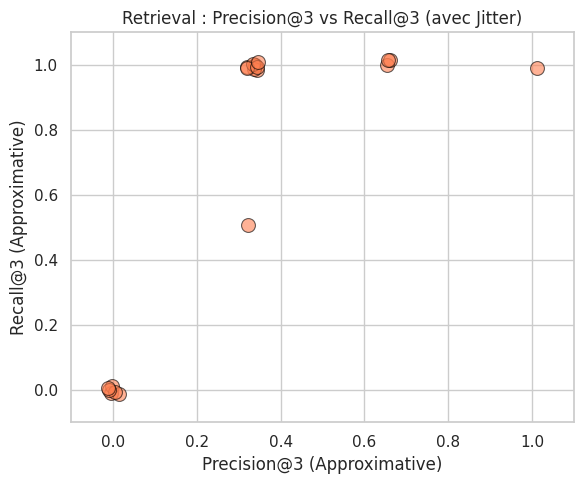

In [ ]:
# 12. Évaluation du Système de Recherche (Retrieval)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def precision_recall_at_k(retrieved_docs, relevant_docs, k=3):
    if not relevant_docs:
        return 0.0, 0.0
    retrieved_k = retrieved_docs[:k]
    retrieved_sources = [doc.metadata.get('source', '') for doc in retrieved_k]

    relevant_retrieved = 0
    for source in retrieved_sources:
        if any(rel.lower() in source.lower() for rel in relevant_docs):
            relevant_retrieved += 1

    precision = relevant_retrieved / k
    recall = relevant_retrieved / len(relevant_docs)
    return precision, min(recall, 1.0)

retrieval_results = []
print(f"Lancement de l'évaluation de la Recherche sur {len(eval_dataset)} questions...")

for item in eval_dataset:
    q = item["question"]
    relevant_docs = item["relevant_docs"]

    # Étape de Rétrieval uniquement
    initial_docs = hybrid_search(q, k=10)
    final_docs = get_reranked_documents(q, initial_docs, top_n=3)
    p_at_3, r_at_3 = precision_recall_at_k(final_docs, relevant_docs, k=3)

    retrieval_results.append({
        "question": q,
        "precision@3": p_at_3,
        "recall@3": r_at_3
    })

df_retrieval = pd.DataFrame(retrieval_results)

print("\n--- Résultats Rétrieval ---")
print(f"Precision@3 moyenne : {df_retrieval['precision@3'].mean():.2f}")
print(f"Recall@3 moyen      : {df_retrieval['recall@3'].mean():.2f}")

# Graphique Rétrieval
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 5))

# Ajout d'un "Jitter" (léger décalage aléatoire) pour empêcher la superposition des points
df_plot = df_retrieval.copy()
df_plot['precision_jitter'] = df_plot['precision@3'] + np.random.uniform(-0.015, 0.015, len(df_plot))
df_plot['recall_jitter'] = df_plot['recall@3'] + np.random.uniform(-0.015, 0.015, len(df_plot))

sns.scatterplot(data=df_plot, x='precision_jitter', y='recall_jitter', s=100, color='coral', alpha=0.6, edgecolor='black')
plt.title('Retrieval : Precision@3 vs Recall@3 (avec Jitter)', fontsize=12)
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.xlabel('Precision@3 (Approximative)')
plt.ylabel('Recall@3 (Approximative)')
plt.tight_layout()
plt.show()


Chargement des métriques NLP (BERTScore, ROUGE)...


[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Lancement de l'évaluation de la Génération sur 20 questions...


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) 


Calcul de la Fidélité et du ROUGE en cours...


...

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- Résultats Génération LLM ---
Temps de réponse moyen     : 15.93 secondes
Fidélité moyenne (BERT-F1) : 0.71
ROUGE-L moyen              : 0.16


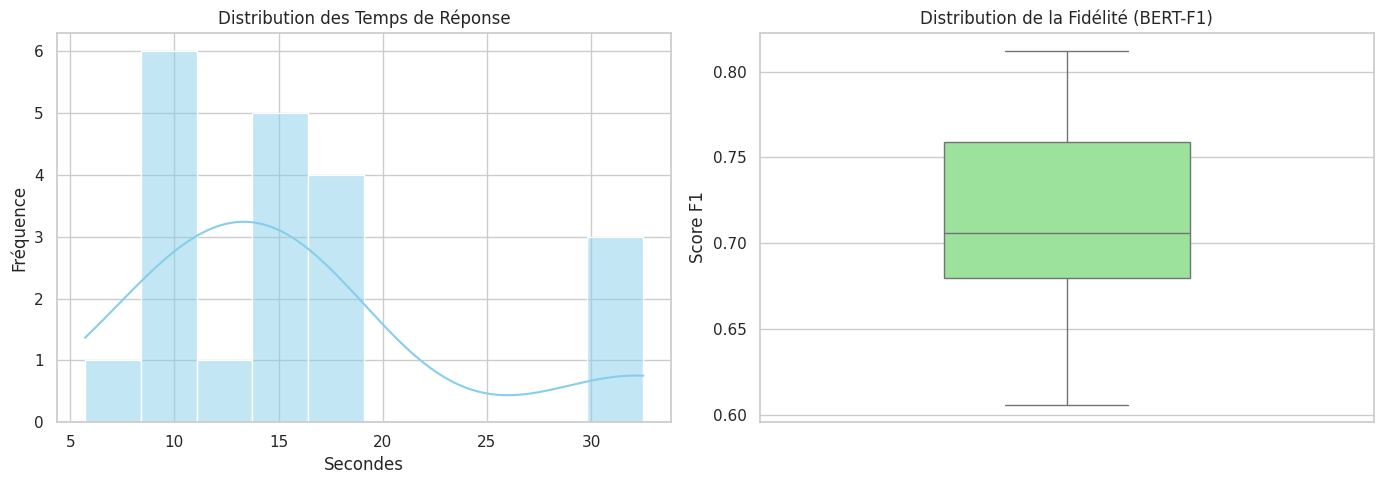

In [ ]:
# 13. Évaluation du Modèle de Génération (LLM)
import time
import evaluate

print("Chargement des métriques NLP (BERTScore, ROUGE)...")
bertscore = evaluate.load('bertscore')
rouge = evaluate.load('rouge')

generation_results = []
predictions = []
references = []

print(f"Lancement de l'évaluation de la Génération sur {len(eval_dataset)} questions...")

for item in eval_dataset:
    q = item["question"]
    ground_truth = item["ground_truth"]

    start_time = time.time()

    # Réinitialisation de l'historique pour l'évaluation unitaire
    global chat_history
    chat_history = []

    ans = ask_bankily_with_memory(q)
    end_time = time.time()

    response_time = end_time - start_time

    predictions.append(ans)
    references.append(ground_truth)

    generation_results.append({
        "question": q,
        "response_time": response_time,
        "answer": ans
    })

# Calcul des scores sémantiques
print("\nCalcul de la Fidélité et du ROUGE en cours...")
rouge_scores = rouge.compute(predictions=predictions, references=references)
bert_scores = bertscore.compute(predictions=predictions, references=references, lang='fr')

for i in range(len(generation_results)):
    generation_results[i]["fidelite_bert_f1"] = bert_scores["f1"][i]

df_gen = pd.DataFrame(generation_results)

print("\n--- Résultats Génération LLM ---")
print(f"Temps de réponse moyen     : {df_gen['response_time'].mean():.2f} secondes")
print(f"Fidélité moyenne (BERT-F1) : {df_gen['fidelite_bert_f1'].mean():.2f}")
print(f"ROUGE-L moyen              : {rouge_scores['rougeL']:.2f}")

# Graphiques Génération
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_gen['response_time'], bins=10, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution des Temps de Réponse', fontsize=12)
axes[0].set_xlabel('Secondes')
axes[0].set_ylabel('Fréquence')

sns.boxplot(y=df_gen['fidelite_bert_f1'], ax=axes[1], color='lightgreen', width=0.4)
axes[1].set_title('Distribution de la Fidélité (BERT-F1)', fontsize=12)
axes[1].set_ylabel('Score F1')

plt.tight_layout()
plt.show()


## Interface Utilisateur (Gradio)

In [ ]:
# ════════════════════════════════════════════════════════════════════════
#  INTERFACE GRADIO — Bankily AI Assistant  (v5 : barres haut/bas FIXES)
#  ⚠️  À COLLER DANS UNE CELLULE À LA FIN DU NOTEBOOK,
#      APRÈS avoir exécuté les cellules 1 → 9 (def de ask_bankily_with_memory).
# ════════════════════════════════════════════════════════════════════════
import gradio as gr
import re
try:
    import torch
    DEVICE_LABEL = "CUDA ✅" if torch.cuda.is_available() else "CPU"
except Exception:
    DEVICE_LABEL = "GPU"

LOGO_URL = "https://www.elmourageb.com/sites/default/files/IMG_20250429_114353.jpg"
USER_AVATAR = "https://api.dicebear.com/7.x/initials/svg?seed=Vous&backgroundColor=0e6b4e"

# ────────────────────────────────────────────────────────────────────────
#  CONTRÔLE DE LA LANGUE — détection FR / AR / EN + consigne stricte
# ────────────────────────────────────────────────────────────────────────
_AR = re.compile(r'[\u0600-\u06FF]')
_FR_HINTS = set("comment quel quelle quels pourquoi mon ma mes le la les un une des du de pour "
                "avec je vous nous ouvrir compte argent carte numero telephone est faire puis "
                "envoyer payer combien ou quand".split())
_EN_HINTS = set("how what why is are can do does my the a an of for with you we open account money "
                "card number phone send pay where when which".split())

def detect_lang(text):
    if _AR.search(text):
        return 'ar'
    words = re.findall(r"[a-zA-Zàâçéèêëîïôûùüÿœæ']+", text.lower())
    fr = sum(w in _FR_HINTS for w in words)
    en = sum(w in _EN_HINTS for w in words)
    if re.search(r'[àâçéèêëîïôûùüÿœæ]', text):
        fr += 2
    return 'en' if en > fr else 'fr'

_DIRECTIVE = {
    'fr': " (IMPORTANT : réponds uniquement et entièrement en français.)",
    'ar': " (مهم جداً: أجب بالكامل وحصراً باللغة العربية.)",
    'en': " (IMPORTANT: answer only and entirely in English.)",
}

def rag_answer(message):
    try:
        lang = detect_lang(message)
        return ask_bankily_with_memory(message + _DIRECTIVE[lang])
    except NameError:
        return ("⚠️ Le moteur RAG n'est pas chargé. Exécutez d'abord les cellules du notebook "
                "(jusqu'à la cellule 9 qui définit `ask_bankily_with_memory`).")
    except Exception as e:
        return f"⚠️ Une erreur est survenue pendant la génération : {e}"

# ════════════════════════════════════════════════════════════════════════
#  CSS — barre HAUT et barre BAS en position FIXED ; le chat défile entre
# ════════════════════════════════════════════════════════════════════════
CSS = """
@import url('https://fonts.googleapis.com/css2?family=Sora:wght@400;600;700;800&family=Inter:wght@400;500;600&display=swap');

html, body {height:100%; margin:0; background:#EEF3F0;}

.gradio-container {
    font-family:'Inter',sans-serif !important;
    width:100% !important; max-width:100% !important;
    margin:0 !important; padding:0 !important;
    min-height:100vh !important; overflow:hidden !important;
    background:linear-gradient(180deg,#F4F8F5 0%, #E9F1EC 100%) !important;
    color:#143028 !important;
}
footer {display:none !important;}

/* ═════════ BARRE HAUT (FIXE) ═════════ */
.navbar {
    position:fixed !important; top:0; left:0; right:0; z-index:50;
    background:linear-gradient(135deg,#0B6E4F 0%, #11A077 100%) !important;
    padding:8px 22px !important; gap:6px !important;
    box-shadow:0 4px 16px rgba(11,110,79,0.22);
    border-radius:0 0 16px 16px !important; margin:0 !important;
}
.navrow {display:flex; align-items:center; gap:20px; width:100%;}
.nav-brand {display:flex; align-items:center; gap:10px;}
.nav-brand img {width:38px; height:38px; border-radius:10px; border:2px solid rgba(255,255,255,0.55); object-fit:cover;}
.nav-name {font-family:'Sora',sans-serif; font-weight:800; font-size:1.02rem; color:#fff; line-height:1.05;}
.nav-name span {color:#FFE9A8;}
.nav-sub {font-size:0.60rem; color:#D8F0E5; letter-spacing:1.2px; text-transform:uppercase;}
.nav-menu a {color:rgba(255,255,255,0.95); text-decoration:none; font-weight:600; font-size:0.86rem; margin:0 9px;}
.nav-menu a:hover {color:#FFE9A8;}
.badge-live {display:inline-flex; align-items:center; gap:6px; background:rgba(255,255,255,0.16);
    border:1px solid rgba(255,255,255,0.30); color:#FFE9A8; font-size:0.60rem; font-weight:700;
    letter-spacing:1px; text-transform:uppercase; padding:3px 9px; border-radius:999px;}
.dot {width:6px; height:6px; background:#9CFFB0; border-radius:50%; display:inline-block;
    box-shadow:0 0 8px #9CFFB0; animation:pulse 1.8s infinite;}
@keyframes pulse {0%,100%{opacity:1;} 50%{opacity:.4;}}
/* 2e ligne : chips + session */
.nav-info {margin-top:5px; display:flex; align-items:center; flex-wrap:wrap; gap:4px;}
.tech-chip {display:inline-block; background:rgba(255,255,255,0.15); border:1px solid rgba(255,255,255,0.30);
    color:#EAFBF2; border-radius:999px; padding:2px 9px; font-size:0.66rem; font-weight:600;}
.sep {color:rgba(255,255,255,0.5); margin:0 6px;}
.sess {color:#EAFBF2; font-size:0.74rem;}
.sess b {color:#FFE9A8;}

#clear-btn {background:rgba(255,255,255,0.16) !important; color:#fff !important;
    border:1px solid rgba(255,255,255,0.45) !important; border-radius:11px !important;
    font-weight:600 !important; font-size:0.80rem !important; white-space:nowrap !important;
    min-width:max-content !important; flex:0 0 auto !important; padding:6px 12px !important;}
#clear-btn:hover {background:rgba(255,255,255,0.28) !important;}

/* ═════════ ZONE CHAT (défile entre les deux barres) ═════════ */
#chatwrap {margin-top:104px !important; padding:0 22px !important;}
#chatbot {
    height:calc(100vh - 300px) !important; min-height:160px !important;
    background:#FFFFFF !important; border:1px solid #D7E6DE !important;
    border-radius:16px !important; box-shadow:0 6px 22px rgba(11,110,79,0.08) !important;
}
#chatbot .bubble-wrap {height:100% !important; max-height:none !important; overflow-y:auto !important;
    background:transparent !important; padding:10px !important;}
#chatbot .message-row {margin-bottom:10px !important;}
#chatbot .message, #chatbot .message * {opacity:1 !important;}
#chatbot .message {border-radius:15px !important; padding:11px 15px !important;
    font-size:0.96rem !important; line-height:1.5 !important;}
#chatbot .user-row .message, #chatbot .user .message, #chatbot [data-testid="user"] .message {
    background:#0E6B4E !important; border:1px solid #0B6E4F !important;}
#chatbot .user-row .message *, #chatbot .user .message *, #chatbot [data-testid="user"] .message * {color:#FFFFFF !important;}
#chatbot .bot-row .message, #chatbot .bot .message, #chatbot [data-testid="bot"] .message {
    background:#F1F7F4 !important; border:1px solid #CFE0D7 !important;}
#chatbot .bot-row .message *, #chatbot .bot .message *, #chatbot [data-testid="bot"] .message * {color:#143028 !important;}
#chatbot .avatar-container img {border-radius:12px !important; border:1px solid #BBD9C9;}

/* ═════════ BARRE BAS (FIXE) : suggestions + saisie ═════════ */
.bottombar {
    position:fixed !important; bottom:0; left:0; right:0; z-index:50;
    background:#EAF2EC !important; border-top:1px solid #D3E4DB !important;
    padding:8px 22px 12px 22px !important; margin:0 !important;
    box-shadow:0 -4px 18px rgba(11,110,79,0.08);
}
.section-label {font-family:'Sora',sans-serif; font-size:0.68rem; font-weight:700; letter-spacing:1.2px;
    text-transform:uppercase; color:#0B6E4F; margin:2px 0 5px 2px;}
.sugg-btn {background:#FFFFFF !important; color:#0B6E4F !important; border:1px solid #BBD9C9 !important;
    border-radius:11px !important; padding:7px 9px !important; font-size:0.77rem !important;
    font-weight:600 !important; transition:all .2s ease !important; min-width:0 !important;}
.sugg-btn:hover {background:#E4F1EA !important; border-color:#0E8A63 !important; transform:translateY(-1px);}
#user-input textarea {
    background:#FFFFFF !important; color:#143028 !important;
    border:1.5px solid #9FC6B4 !important; border-radius:13px !important;
    font-size:1rem !important; box-shadow:0 4px 14px rgba(11,110,79,0.06) !important;}
#user-input textarea::placeholder {color:#7C9488 !important; opacity:1 !important;}
#send-btn {background:linear-gradient(135deg,#0B6E4F,#11A077) !important; color:#fff !important;
    border:none !important; border-radius:13px !important; font-weight:700 !important;}
#send-btn:hover {filter:brightness(1.07);}
"""

# ════════════════════════════════════════════════════════════════════════
#  CALLBACKS
# ════════════════════════════════════════════════════════════════════════
THINKING = "✍️ Rédaction de la réponse en cours…"
CHIPS = ('<span class="tech-chip">Mistral-7B</span><span class="tech-chip">BGE-M3</span>'
         '<span class="tech-chip">FAISS</span><span class="tech-chip">BM25</span>'
         '<span class="tech-chip">LangChain</span><span class="tech-chip">4-bit NF4</span>')

def session_line(history):
    return (f'<div class="nav-info">{CHIPS}<span class="sep">·</span>'
            f'<span class="sess">💬 <b>{len(history)}</b> messages '
            f'<span class="sep">·</span> 🖥️ <b>{DEVICE_LABEL}</b></span></div>')

def add_user(message, history):
    message = (message or "").strip()
    if not message:
        return history, ""
    history = history + [{"role": "user", "content": message},
                         {"role": "assistant", "content": THINKING}]
    return history, ""

def add_user_text(text, history):
    return history + [{"role": "user", "content": text},
                      {"role": "assistant", "content": THINKING}]

def bot_reply(history):
    if not history:
        return history, session_line(history)
    user_msg = next((m["content"] for m in reversed(history[:-1]) if m["role"] == "user"), None)
    answer = rag_answer(user_msg) if user_msg else "…"
    new_history = history[:-1] + [{"role": "assistant", "content": answer}]
    return new_history, session_line(new_history)

def clear_chat():
    try:
        chat_history.clear()
    except Exception:
        pass
    return [], session_line([])

# ════════════════════════════════════════════════════════════════════════
#  INTERFACE
# ════════════════════════════════════════════════════════════════════════
with gr.Blocks(css=CSS, title="Bankily AI Assistant", theme=gr.themes.Base()) as demo:

    # ----- BARRE HAUT (fixe) : menu + chips/session -----
    with gr.Column(elem_classes="navbar"):
        with gr.Row():
            gr.HTML(f"""
            <div class="navrow">
              <div class="nav-brand">
                <img src="{LOGO_URL}" alt="Bankily">
                <div><div class="nav-name">Bankily <span>AI</span></div>
                     <div class="nav-sub">Assistant · BPM</div></div>
              </div>
              <span class="badge-live"><span class="dot"></span> En ligne</span>
              <div class="nav-menu">
                <a href="https://www.bankily.mr/" target="_blank">Accueil</a>
                <a href="https://www.bankily.mr/" target="_blank">Services</a>
                <a href="https://www.bankily.mr/" target="_blank">Aide</a>
              </div>
            </div>""")
            clear_btn = gr.Button("🗑️ Nouvelle conversation", elem_id="clear-btn", scale=0)
        session_html = gr.HTML(session_line([]))

    # ----- ZONE DE CHAT (défile) -----
    with gr.Column(elem_id="chatwrap"):
        chatbot = gr.Chatbot(elem_id="chatbot", type="messages", show_label=False,
                             avatar_images=(USER_AVATAR, LOGO_URL))

    # ----- BARRE BAS (fixe) : suggestions + saisie -----
    with gr.Column(elem_classes="bottombar"):
        gr.HTML('<div class="section-label">💡 Questions fréquentes</div>')
        with gr.Row():
            s1 = gr.Button("📱 Ouvrir un compte", elem_classes="sugg-btn")
            s2 = gr.Button("💸 Envoyer de l'argent", elem_classes="sugg-btn")
            s3 = gr.Button("🔐 Code PIN oublié", elem_classes="sugg-btn")
            s4 = gr.Button("🏪 Payer chez un marchand", elem_classes="sugg-btn")
        with gr.Row():
            user_input = gr.Textbox(placeholder="✍️ Posez votre question sur Bankily...",
                                    elem_id="user-input", show_label=False, scale=8, container=False)
            send_btn = gr.Button("Envoyer", elem_id="send-btn", scale=2)

    # ----- Événements -----
    send_btn.click(add_user, [user_input, chatbot], [chatbot, user_input]) \
            .then(bot_reply, chatbot, [chatbot, session_html])
    user_input.submit(add_user, [user_input, chatbot], [chatbot, user_input]) \
              .then(bot_reply, chatbot, [chatbot, session_html])
    clear_btn.click(clear_chat, None, [chatbot, session_html])
    s1.click(lambda h: add_user_text("Comment ouvrir un compte Bankily ?", h), chatbot, chatbot) \
      .then(bot_reply, chatbot, [chatbot, session_html])
    s2.click(lambda h: add_user_text("Comment envoyer de l'argent ?", h), chatbot, chatbot) \
      .then(bot_reply, chatbot, [chatbot, session_html])
    s3.click(lambda h: add_user_text("Que faire si j'oublie mon code PIN ?", h), chatbot, chatbot) \
      .then(bot_reply, chatbot, [chatbot, session_html])
    s4.click(lambda h: add_user_text("Comment payer chez un marchand ?", h), chatbot, chatbot) \
      .then(bot_reply, chatbot, [chatbot, session_html])

demo.launch(share=True, debug=True)

/tmp/ipykernel_11817/123610172.py:194: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(css=CSS, title="Bankily AI Assistant", theme=gr.themes.Base()) as demo:
/tmp/ipykernel_11817/123610172.py:194: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=CSS, title="Bankily AI Assistant", theme=gr.themes.Base()) as demo:
/tmp/ipykernel_11817/123610172.py:218: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chatbot = gr.Chatbot(elem_id="chatbot", type="messages", show_label=False,


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a60ec1b2061f15fbd4.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


[transformers] Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to forc